# パイプラインの高速化・スケーラビリティとボトルネック計測

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch5_toolkit_benchmark.ipynb)

書籍 第5章「言語資源のつくり方」（5-5-1 脚注 203、5-5-2 高速化とスケーラビリティ・脚注 207）に対応する演習ノートブックです。
CPU のみ・十数秒で実行でき、パイプライン設計と数値計算における性能ボトルネックの計測・改善を体験します。

1. **プロセス起動 (`exec`) コスト vs 常駐ワーカー vs メモリ内バッチ（5-5-1 脚注 203）**: 固定起動コスト $T_{\text{init}}$ と件数あたり処理コスト $T_{\text{item}}$ の分離・スケーリング測定
2. **Python 多重ループ vs NumPy / BLAS 行列積と疎行列（5-5-2 脚注 207）**: 密ループ・疎辞書ループ・BLAS `@`・`scipy.sparse` CSR 行列積の数値一致検証と速度比測定
3. **I/O バウンド vs 計算バウンドのプロファイリングとアムダールの法則 (5-5-2)**: `cProfile` によるボトルネック特定と段階的最適化による理論限界の検証

---

## 1. プロセス起動 (`exec`) コスト vs 常駐ワーカー vs メモリ内バッチ（5-5-1 脚注 203）

書籍 5-5-1（脚注 203）では、テキスト 1 文ごとに外部プロセスを起動 (`exec`) すると、**OS のプロセス生成とライブラリ・辞書・モデルの再読み込み ($T_{\text{init}}$) が毎回発生して極端に遅くなる**点が指摘されています。

- **都度起動（`subprocess.run` / 文）**: $T(N) \approx N \cdot (T_{\text{init}} + T_{\text{item}})$
- **常駐ワーカー（`subprocess.Popen` ストリーミング）**: 起動時に 1 回だけ辞書を読み込み、`stdin`/`stdout` で JSON Lines をやり取りするため $T(N) \approx T_{\text{init}} + N \cdot T_{\text{item}}$
- **メモリ内バッチ処理**: IPC・プロセス生成すら不要で $T(N) \approx T_{\text{load}} + N \cdot T_{\text{item}}$

10,000 語規模の辞書を読み込むワーカーを一時ディレクトリに用意し、$N \in \{1, 10, 50, 100\}$ 件で実測・線形回帰します。

,N,Per-item exec [ms],Persistent Popen [ms],In-memory batch [ms],Speedup (Popen vs exec)
0,1,55.81,41.28,3.53,1.4
1,10,418.51,49.72,3.77,8.4
2,50,2199.13,41.09,6.94,53.5
3,100,4284.48,46.35,12.39,92.4


推定コスト (Per-item exec):   46.12 ms/item（毎回プロセス起動＋辞書ロードが発生）
推定コスト (Persistent Popen): T_init = 44.31 ms, T_item = 0.007 ms/item
N=10,000 外挿: Per-item exec ≈ 461.2 秒 vs Persistent Popen ≈ 0.12 秒


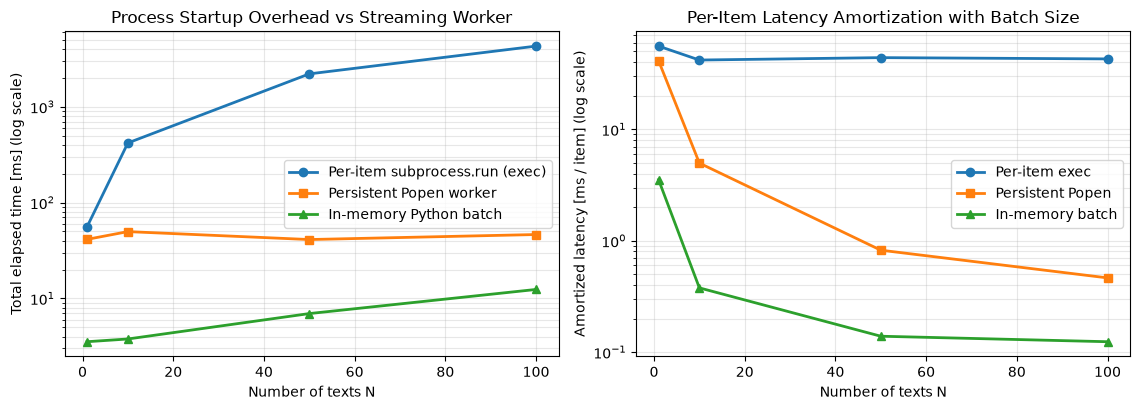

In [1]:
import cProfile
import io
import json
import os
import pstats
import re
import subprocess
import sys
import tempfile
import time
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

tmpdir = tempfile.TemporaryDirectory()
wdir = Path(tmpdir.name)

# 10,000語の擬似辞書を作成して起動時の初期化コストを再現
lex = {f"term_{i}": (i % 7 - 3) * 0.25 for i in range(10000)}
lex.update({"良い": 1.0, "快適": 1.2, "満足": 1.5, "悪い": -1.0, "残念": -1.2, "最悪": -1.5})
lex_path = wdir / "lexicon.json"
lex_path.write_text(json.dumps(lex, ensure_ascii=False), encoding="utf-8")

worker_path = wdir / "worker.py"
worker_path.write_text(r'''import argparse, json, re, sys, unicodedata
from pathlib import Path

parser = argparse.ArgumentParser()
parser.add_argument("--lexicon", required=True)
parser.add_argument("--mode", choices=["once", "stream"], required=True)
args = parser.parse_args()

lex = json.loads(Path(args.lexicon).read_text(encoding="utf-8"))
tok_re = re.compile(r"[A-Za-z0-9_]+|[ァ-ヶー]+|[一-龥]+")

def score_record(rec):
    norm = unicodedata.normalize("NFKC", rec["text"])
    toks = tok_re.findall(norm)
    s = 0.0
    for _ in range(40):
        s += sum(lex.get(t, 0.0) for t in toks)
    return {"id": rec["id"], "score": round(s / 40.0, 3)}

if args.mode == "once":
    rec = json.loads(sys.stdin.readline())
    sys.stdout.write(json.dumps(score_record(rec)) + "\n")
else:
    sys.stdout.write(json.dumps({"ready": True}) + "\n")
    sys.stdout.flush()
    for line in sys.stdin:
        if not line.strip():
            continue
        rec = json.loads(line)
        sys.stdout.write(json.dumps(score_record(rec)) + "\n")
        sys.stdout.flush()
''', encoding="utf-8")

sample_pool = [
    {"id": i, "text": f"良い 快適 term_{i % 500} term_{(i * 3) % 500} term_{(i * 7) % 500} 満足 ＷｉーＦｉ"}
    for i in range(100)
]

tok_re = re.compile(r"[A-Za-z0-9_]+|[ァ-ヶー]+|[一-龥]+")
def run_in_memory(batch):
    mem_lex = json.loads(lex_path.read_text(encoding="utf-8"))
    out = []
    for rec in batch:
        norm = unicodedata.normalize("NFKC", rec["text"])
        toks = tok_re.findall(norm)
        s = 0.0
        for _ in range(40):
            s += sum(mem_lex.get(t, 0.0) for t in toks)
        out.append({"id": rec["id"], "score": round(s / 40.0, 3)})
    return out

# ウォームアップ
_ = run_in_memory(sample_pool[:2])

ns = [1, 10, 50, 100]
bench1_rows = []
for n in ns:
    batch = sample_pool[:n]

    # (a) 1文ごとにプロセス起動
    t0 = time.perf_counter()
    out_exec = []
    for rec in batch:
        res = subprocess.run(
            [sys.executable, str(worker_path), "--lexicon", str(lex_path), "--mode", "once"],
            input=json.dumps(rec) + "\n",
            text=True,
            capture_output=True,
            check=True,
        )
        out_exec.append(json.loads(res.stdout.strip()))
    t_exec = (time.perf_counter() - t0) * 1000

    # (b) 常駐 Popen ワーカー（3回の中央値）
    stream_times = []
    for _ in range(3):
        t0 = time.perf_counter()
        proc = subprocess.Popen(
            [sys.executable, str(worker_path), "--lexicon", str(lex_path), "--mode", "stream"],
            stdin=subprocess.PIPE,
            stdout=subprocess.PIPE,
            text=True,
        )
        _ = proc.stdout.readline()
        out_stream = []
        for rec in batch:
            proc.stdin.write(json.dumps(rec) + "\n")
            proc.stdin.flush()
            out_stream.append(json.loads(proc.stdout.readline()))
        proc.stdin.close()
        assert proc.wait() == 0
        stream_times.append((time.perf_counter() - t0) * 1000)
    t_stream = float(np.median(stream_times))

    # (c) メモリ内バッチ（3回の中央値）
    mem_times = []
    for _ in range(3):
        t0 = time.perf_counter()
        out_mem = run_in_memory(batch)
        mem_times.append((time.perf_counter() - t0) * 1000)
    t_mem = float(np.median(mem_times))

    assert out_exec == out_stream == out_mem
    bench1_rows.append({
        "N": n,
        "Per-item exec [ms]": round(t_exec, 2),
        "Persistent Popen [ms]": round(t_stream, 2),
        "In-memory batch [ms]": round(t_mem, 2),
        "Speedup (Popen vs exec)": round(t_exec / t_stream, 1),
    })

df_b1 = pd.DataFrame(bench1_rows)
display(df_b1)

# 線形回帰による起動コスト・1件あたり処理コストの推定
mean_per_item_exec = float(np.mean(df_b1["Per-item exec [ms]"] / df_b1["N"]))
slope_stream, intercept_stream = np.polyfit(df_b1["N"], df_b1["Persistent Popen [ms]"], 1)
print(f"推定コスト (Per-item exec):   {mean_per_item_exec:.2f} ms/item（毎回プロセス起動＋辞書ロードが発生）")
print(f"推定コスト (Persistent Popen): T_init = {intercept_stream:.2f} ms, T_item = {slope_stream:.3f} ms/item")
print(f"N=10,000 外挿: Per-item exec ≈ {mean_per_item_exec * 10000 / 1000:.1f} 秒 vs Persistent Popen ≈ {(intercept_stream + slope_stream * 10000) / 1000:.2f} 秒")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(df_b1["N"], df_b1["Per-item exec [ms]"], marker="o", linewidth=2, label="Per-item subprocess.run (exec)")
axes[0].plot(df_b1["N"], df_b1["Persistent Popen [ms]"], marker="s", linewidth=2, label="Persistent Popen worker")
axes[0].plot(df_b1["N"], df_b1["In-memory batch [ms]"], marker="^", linewidth=2, label="In-memory Python batch")
axes[0].set_yscale("log")
axes[0].set_xlabel("Number of texts N")
axes[0].set_ylabel("Total elapsed time [ms] (log scale)")
axes[0].set_title("Process Startup Overhead vs Streaming Worker")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

axes[1].plot(df_b1["N"], df_b1["Per-item exec [ms]"] / df_b1["N"], marker="o", linewidth=2, label="Per-item exec")
axes[1].plot(df_b1["N"], df_b1["Persistent Popen [ms]"] / df_b1["N"], marker="s", linewidth=2, label="Persistent Popen")
axes[1].plot(df_b1["N"], df_b1["In-memory batch [ms]"] / df_b1["N"], marker="^", linewidth=2, label="In-memory batch")
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of texts N")
axes[1].set_ylabel("Amortized latency [ms / item] (log scale)")
axes[1].set_title("Per-Item Latency Amortization with Batch Size")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

---

## 2. Python 多重ループ vs NumPy / BLAS 行列演算と疎行列（5-5-2 脚注 207）

書籍 5-5-2（脚注 207）では、Python の素朴な多重ループで要素ごとに計算する代わりに、**NumPy / BLAS の行列積** (`@`) や**疎行列ライブラリ** (`scipy.sparse`) を使うことで桁違いの高速化が得られることが解説されています。

文書数 $N \in \{100, 500, 1000, 2000\}$、語彙次元 $V = 500$（非ゼロ率約 5% の BoW 特徴行列）と $Q = 30$ 個のクエリベクトルとのコサイン類似度行列を計算し、4 実装を比較します。さらに、$N = 1000$ の全対類似度 ($X X^T$) において、データ密度に応じた **密行列 BLAS `@` vs 疎行列 `CSR @`** の逆転点も確認します。

全構成で np.allclose(atol=1e-12) 一致を確認しました。


,N,Py Dense [ms],Py Sparse [ms],NumPy BLAS @ [ms],SciPy CSR @ [ms],Speedup (BLAS vs PyDense),Speedup (CSR vs PyDense)
0,100,204.55,8.45,0.039,0.207,5198.2,990.3
1,500,863.08,42.91,4.789,0.619,180.2,1394.6
2,1000,1680.27,78.62,12.048,1.146,139.5,1465.6
3,2000,3157.99,137.02,13.108,2.314,240.9,1364.4


,Density,Dense BLAS [ms],Sparse CSR [ms]
0,0.01,28.72,37.03
1,0.05,13.82,57.27
2,0.20,15.25,69.39
3,0.50,16.24,248.71
4,0.80,12.48,540.17


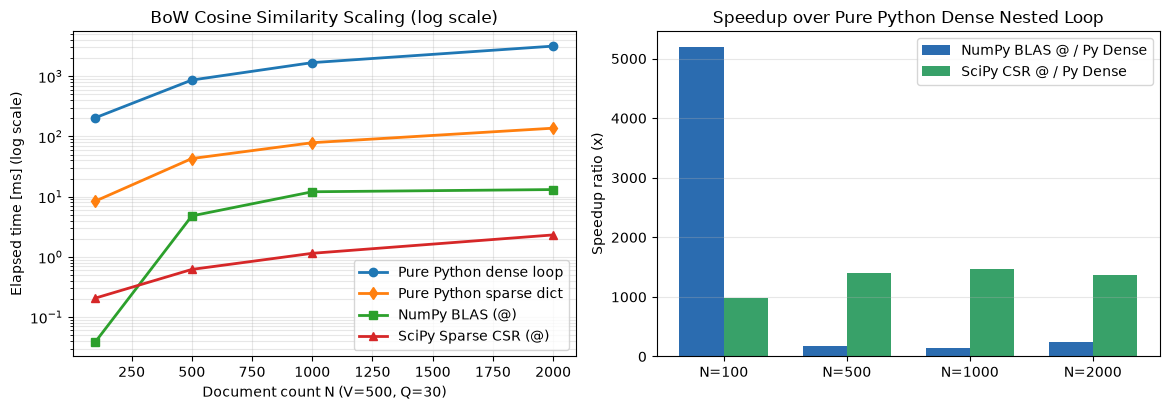

In [2]:
rng = np.random.default_rng(42)
V = 500
Q = 30

# BLAS の初回初期化を除外するためのウォームアップ
_ = rng.random((64, V)) @ rng.random((V, 64))

Q_raw = (rng.random((Q, V)) < 0.08).astype(np.float64) * rng.integers(1, 5, size=(Q, V))
Q_norm = Q_raw / np.maximum(np.linalg.norm(Q_raw, axis=1, keepdims=True), 1e-12)
Q_list = Q_norm.tolist()
Q_sparse_dicts = [{j: float(v) for j, v in enumerate(row) if v != 0.0} for row in Q_norm]
Q_csr = sparse.csr_matrix(Q_norm)

b2_rows = []
for N in [100, 500, 1000, 2000]:
    X_raw = (rng.random((N, V)) < 0.05).astype(np.float64) * rng.integers(1, 5, size=(N, V))
    X_norm = X_raw / np.maximum(np.linalg.norm(X_raw, axis=1, keepdims=True), 1e-12)
    X_list = X_norm.tolist()
    X_sparse_dicts = [{j: float(v) for j, v in enumerate(row) if v != 0.0} for row in X_norm]
    X_csr = sparse.csr_matrix(X_norm)

    # 1) Pure Python 密多重ループ
    t0 = time.perf_counter()
    res_py_dense = []
    for rx in X_list:
        row_out = []
        for rq in Q_list:
            s = 0.0
            for k in range(V):
                s += rx[k] * rq[k]
            row_out.append(s)
        res_py_dense.append(row_out)
    t_py_dense = (time.perf_counter() - t0) * 1000

    # 2) Pure Python 疎辞書内積
    t0 = time.perf_counter()
    res_py_sparse = []
    for dx in X_sparse_dicts:
        row_out = []
        for dq in Q_sparse_dicts:
            s = 0.0
            for k, vx in dx.items():
                if k in dq:
                    s += vx * dq[k]
            row_out.append(s)
        res_py_sparse.append(row_out)
    t_py_sparse = (time.perf_counter() - t0) * 1000

    # 3) NumPy / BLAS 行列積（高速処理のため 5 回の中央値を計測）
    np_times = []
    for _ in range(5):
        t0 = time.perf_counter()
        res_np = X_norm @ Q_norm.T
        np_times.append((time.perf_counter() - t0) * 1000)
    t_np = float(np.median(np_times))

    # 4) SciPy 疎行列 CSR @（5 回の中央値）
    csr_times = []
    for _ in range(5):
        t0 = time.perf_counter()
        res_csr = (X_csr @ Q_csr.T).toarray()
        csr_times.append((time.perf_counter() - t0) * 1000)
    t_csr = float(np.median(csr_times))

    # 数値一致の検証
    assert np.allclose(np.array(res_py_dense), res_np, atol=1e-12)
    assert np.allclose(np.array(res_py_sparse), res_np, atol=1e-12)
    assert np.allclose(res_csr, res_np, atol=1e-12)

    b2_rows.append({
        "N": N,
        "Py Dense [ms]": round(t_py_dense, 2),
        "Py Sparse [ms]": round(t_py_sparse, 2),
        "NumPy BLAS @ [ms]": round(t_np, 3),
        "SciPy CSR @ [ms]": round(t_csr, 3),
        "Speedup (BLAS vs PyDense)": round(t_py_dense / t_np, 1),
        "Speedup (CSR vs PyDense)": round(t_py_dense / t_csr, 1),
    })

df_b2 = pd.DataFrame(b2_rows)
print("全構成で np.allclose(atol=1e-12) 一致を確認しました。")
display(df_b2)

# 全対類似度 (1000 x 1000) における密度別の密行列 BLAS vs 疎行列 CSR 比較
densities = [0.01, 0.05, 0.20, 0.50, 0.80]
dens_rows = []
for d in densities:
    M_raw = (rng.random((1000, V)) < d).astype(np.float64) * rng.integers(1, 5, size=(1000, V))
    M_norm = M_raw / np.maximum(np.linalg.norm(M_raw, axis=1, keepdims=True), 1e-12)
    M_csr = sparse.csr_matrix(M_norm)
    t0 = time.perf_counter()
    s_dense = M_norm @ M_norm.T
    t_d = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    s_csr = (M_csr @ M_csr.T).toarray()
    t_s = (time.perf_counter() - t0) * 1000
    assert np.allclose(s_dense, s_csr, atol=1e-12)
    dens_rows.append({"Density": d, "Dense BLAS [ms]": round(t_d, 2), "Sparse CSR [ms]": round(t_s, 2)})

df_dens = pd.DataFrame(dens_rows)
display(df_dens)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2))
axes[0].plot(df_b2["N"], df_b2["Py Dense [ms]"], marker="o", linewidth=2, label="Pure Python dense loop")
axes[0].plot(df_b2["N"], df_b2["Py Sparse [ms]"], marker="d", linewidth=2, label="Pure Python sparse dict")
axes[0].plot(df_b2["N"], df_b2["NumPy BLAS @ [ms]"], marker="s", linewidth=2, label="NumPy BLAS (@)")
axes[0].plot(df_b2["N"], df_b2["SciPy CSR @ [ms]"], marker="^", linewidth=2, label="SciPy Sparse CSR (@)")
axes[0].set_yscale("log")
axes[0].set_xlabel("Document count N (V=500, Q=30)")
axes[0].set_ylabel("Elapsed time [ms] (log scale)")
axes[0].set_title("BoW Cosine Similarity Scaling (log scale)")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

x = np.arange(len(df_b2))
w = 0.36
axes[1].bar(x - w / 2, df_b2["Speedup (BLAS vs PyDense)"], w, label="NumPy BLAS @ / Py Dense", color="#2b6cb0")
axes[1].bar(x + w / 2, df_b2["Speedup (CSR vs PyDense)"], w, label="SciPy CSR @ / Py Dense", color="#38a169")
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"N={n}" for n in df_b2["N"]])
axes[1].set_ylabel("Speedup ratio (x)")
axes[1].set_title("Speedup over Pure Python Dense Nested Loop")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

---

## 3. I/O バウンド vs 計算バウンドのプロファイリングとアムダールの法則 (5-5-2)

書籍 5-5-2 では、最適化の前にまず**プロファイリングでボトルネック（I/O バウンドか計算バウンドか）を特定すること**が説かれています。
ある処理が全体実行時間に占める割合を $p$ とすると、その部分だけを無限に高速化しても全体の高速化倍率には上限（**アムダールの法則**）があります。

$$S_{\max} = \frac{1}{1 - p}$$

ここでは、**非効率な逐次ファイル追記（1 件ごとに `open`/`flush`/`fsync`）＋ 非効率な Python 計算**（構成 A）を出発点として、`cProfile` とステージ別計時でボトルネックを切り分け、**バッファ付きストリーミング I/O（構成 B）** → **正規表現プリコンパイル＋ハッシュ辞書化（構成 C）** の順に段階的に高速化します。

,Stage,I/O [ms],Compute [ms],Total [ms],I/O Share,Speedup vs (A)
0,(A) Unbuffered fsync + Slow,430.32,95.33,525.64,81.9%,1.0x
1,(B) Buffered I/O + Slow,0.17,104.00,104.17,0.2%,5.0x
2,(C) Buffered I/O + Fast,0.11,6.82,6.93,1.6%,75.9x


構成 (A) のアムダール理論上限: 計算のみ高速化しても最大 1.22x / I/O 改善で最大 5.5x (実測 A->B: 5.0x)
構成 (B) のアムダール理論上限: ボトルネックが計算 (99.8%) へ移り、計算改善で最大 611.4x (実測 B->C: 15.0x)

--- cProfile Top 5 in (A) Unbuffered I/O ---

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      800    0.411    0.001    0.411    0.001 {built-in method posix.fsync}
     4000    0.089    0.000    0.089    0.000 /tmp/ipykernel_4025140/1032700114.py:16(<genexpr>)
      800    0.012    0.000    0.013    0.000 {built-in method _io.open}
      800    0.006    0.000    0.006    0.000 {method 'flush' of '_io.TextIOWrapper' objects}
        1    0.004    0.004    0.541    0.541 /tmp/ipykernel_4025140/1032700114.py:38(run_a)

--- cProfile Top 5 in (B) Buffered I/O ---

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     4000    0.103    0.000    0.103    0.000 /tmp/ipykernel_4025140/1032700114.py:16(<genexpr>)
      800    0.003    0.000    0.003    0.000 {built-in method unicodedata.normalize}
    

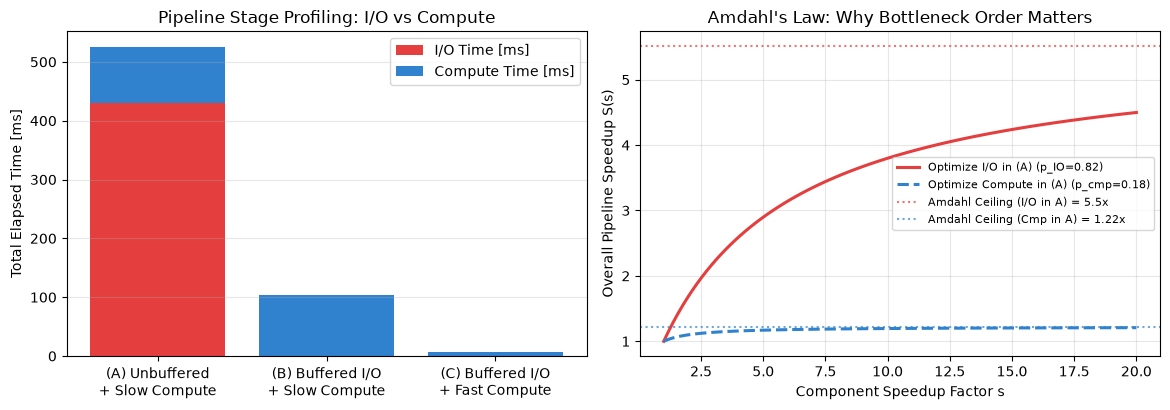

In [3]:
N_rec = 800
records = [f"Record {i}: <p>ＷｉーＦｉが安定して快適でした！</p> term_{i % 150} https://example.com/{i}\n" for i in range(N_rec)]
vocab_list = [f"term_{k}" for k in range(600)]
vocab_set = set(vocab_list)

re_tag_pat = r"<[^>]+>"
re_url_pat = r"https?://\S+"
re_tok_pat = r"[A-Za-z0-9_]+|[ァ-ヶー]+|[一-龥]+"

def compute_slow(text):
    t = unicodedata.normalize("NFKC", text)
    t = re.sub(re_tag_pat, " ", t)
    t = re.sub(re_url_pat, " ", t)
    toks = re.findall(re_tok_pat, t)
    # O(|toks| * |V|) の線形探索（ボトルネック計算を模擬）
    hits = sum(1 for tok in toks for _ in range(4) if tok in vocab_list)
    return {"len": len(toks), "hits": hits // 4}

re_clean_compiled = re.compile(r"<[^>]+>|https?://\S+")
re_tok_compiled = re.compile(re_tok_pat)

def compute_fast(text):
    t = re_clean_compiled.sub(" ", unicodedata.normalize("NFKC", text))
    toks = re_tok_compiled.findall(t)
    # O(1) ハッシュ集合探索
    hits = sum(1 for tok in toks if tok in vocab_set)
    return {"len": len(toks), "hits": hits}

# ウォームアップ
_ = [compute_slow(r) for r in records[:50]]
_ = [compute_fast(r) for r in records[:50]]

out_a = wdir / "pipe_a_unbuf.jsonl"
out_b = wdir / "pipe_b_buf.jsonl"
out_c = wdir / "pipe_c_opt.jsonl"

# (A) 逐次 open + fsync (I/Oバウンド) + compute_slow
def run_a():
    if out_a.exists():
        out_a.unlink()
    tc0 = time.perf_counter()
    res_list = [compute_slow(r) for r in records]
    t_cmp = time.perf_counter() - tc0
    ti0 = time.perf_counter()
    for res in res_list:
        with open(out_a, "a", encoding="utf-8") as f:
            f.write(json.dumps(res) + "\n")
            f.flush()
            os.fsync(f.fileno())
    t_io = time.perf_counter() - ti0
    return t_io * 1000, t_cmp * 1000

# (B) バッファ付き一括 I/O + compute_slow (計算バウンドへ移行)
def run_b():
    tc0 = time.perf_counter()
    lines = [json.dumps(compute_slow(r)) + "\n" for r in records]
    t_cmp = time.perf_counter() - tc0
    ti0 = time.perf_counter()
    with open(out_b, "w", encoding="utf-8", buffering=65536) as f:
        f.writelines(lines)
    t_io = time.perf_counter() - ti0
    return t_io * 1000, t_cmp * 1000

# (C) バッファ付き I/O + compute_fast
def run_c():
    tc0 = time.perf_counter()
    lines = [json.dumps(compute_fast(r)) + "\n" for r in records]
    t_cmp = time.perf_counter() - tc0
    ti0 = time.perf_counter()
    with open(out_c, "w", encoding="utf-8", buffering=65536) as f:
        f.writelines(lines)
    t_io = time.perf_counter() - ti0
    return t_io * 1000, t_cmp * 1000

# まず純粋な実行時間を計測し、その後 cProfile を別パスで実行してプロファイルオーバーヘッドを分離
io_a, cmp_a = run_a()
io_b, cmp_b = run_b()
io_c, cmp_c = run_c()

prof_a = cProfile.Profile()
prof_a.enable()
_ = run_a()
prof_a.disable()

prof_b = cProfile.Profile()
prof_b.enable()
_ = run_b()
prof_b.disable()

tot_a, tot_b, tot_c = io_a + cmp_a, io_b + cmp_b, io_c + cmp_c
p_io_a = io_a / tot_a
p_cmp_a = cmp_a / tot_a
p_cmp_b = cmp_b / tot_b

amdahl_max_cmp_only_in_a = 1.0 / (1.0 - p_cmp_a)
amdahl_max_io_in_a = 1.0 / (1.0 - p_io_a)
amdahl_max_cmp_in_b = 1.0 / (1.0 - p_cmp_b)

summary_b3 = pd.DataFrame([
    {"Stage": "(A) Unbuffered fsync + Slow", "I/O [ms]": round(io_a, 2), "Compute [ms]": round(cmp_a, 2), "Total [ms]": round(tot_a, 2), "I/O Share": f"{p_io_a*100:.1f}%", "Speedup vs (A)": "1.0x"},
    {"Stage": "(B) Buffered I/O + Slow",     "I/O [ms]": round(io_b, 2), "Compute [ms]": round(cmp_b, 2), "Total [ms]": round(tot_b, 2), "I/O Share": f"{(io_b/tot_b)*100:.1f}%", "Speedup vs (A)": f"{tot_a/tot_b:.1f}x"},
    {"Stage": "(C) Buffered I/O + Fast",     "I/O [ms]": round(io_c, 2), "Compute [ms]": round(cmp_c, 2), "Total [ms]": round(tot_c, 2), "I/O Share": f"{(io_c/tot_c)*100:.1f}%", "Speedup vs (A)": f"{tot_a/tot_c:.1f}x"},
])
display(summary_b3)

print(f"構成 (A) のアムダール理論上限: 計算のみ高速化しても最大 {amdahl_max_cmp_only_in_a:.2f}x / I/O 改善で最大 {amdahl_max_io_in_a:.1f}x (実測 A->B: {tot_a/tot_b:.1f}x)")
print(f"構成 (B) のアムダール理論上限: ボトルネックが計算 ({p_cmp_b*100:.1f}%) へ移り、計算改善で最大 {amdahl_max_cmp_in_b:.1f}x (実測 B->C: {tot_b/tot_c:.1f}x)")

for title, pr in [("--- cProfile Top 5 in (A) Unbuffered I/O ---", prof_a), ("--- cProfile Top 5 in (B) Buffered I/O ---", prof_b)]:
    print(f"\n{title}")
    sio = io.StringIO()
    pstats.Stats(pr, stream=sio).sort_stats("tottime").print_stats(5)
    print("\n".join(sio.getvalue().splitlines()[4:11]))

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2))
labels = ["(A) Unbuffered\n+ Slow Compute", "(B) Buffered I/O\n+ Slow Compute", "(C) Buffered I/O\n+ Fast Compute"]
io_vals = [io_a, io_b, io_c]
cmp_vals = [cmp_a, cmp_b, cmp_c]
axes[0].bar(labels, io_vals, label="I/O Time [ms]", color="#e53e3e")
axes[0].bar(labels, cmp_vals, bottom=io_vals, label="Compute Time [ms]", color="#3182ce")
axes[0].set_ylabel("Total Elapsed Time [ms]")
axes[0].set_title("Pipeline Stage Profiling: I/O vs Compute")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Amdahl's Law theoretical ceiling vs achieved speedup
s_vals = np.linspace(1.0, 20.0, 100)
amdahl_curve_cmp_in_a = 1.0 / ((1.0 - p_cmp_a) + p_cmp_a / s_vals)
amdahl_curve_io_in_a = 1.0 / ((1.0 - p_io_a) + p_io_a / s_vals)
axes[1].plot(s_vals, amdahl_curve_io_in_a, linewidth=2.2, color="#e53e3e", label=f"Optimize I/O in (A) (p_IO={p_io_a:.2f})")
axes[1].plot(s_vals, amdahl_curve_cmp_in_a, linewidth=2.2, linestyle="--", color="#3182ce", label=f"Optimize Compute in (A) (p_cmp={p_cmp_a:.2f})")
axes[1].axhline(amdahl_max_io_in_a, color="#e53e3e", linestyle=":", alpha=0.7, label=f"Amdahl Ceiling (I/O in A) = {amdahl_max_io_in_a:.1f}x")
axes[1].axhline(amdahl_max_cmp_only_in_a, color="#3182ce", linestyle=":", alpha=0.7, label=f"Amdahl Ceiling (Cmp in A) = {amdahl_max_cmp_only_in_a:.2f}x")
axes[1].set_xlabel("Component Speedup Factor s")
axes[1].set_ylabel("Overall Pipeline Speedup S(s)")
axes[1].set_title("Amdahl's Law: Why Bottleneck Order Matters")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

tmpdir.cleanup()